<a href="https://colab.research.google.com/github/MominaShahzad100/Python-Git-Project/blob/main/AI_LAB_Assignment_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

# Load Breast Cancer Wisconsin dataset
cancer = load_breast_cancer(as_frame=True)
X_cancer = cancer.data
y_cancer = cancer.target

print("Dataset loaded successfully.")
print("Number of rows:", X_cancer.shape[0])
print("Number of input features:", X_cancer.shape[1])
print("Target classes:", dict(enumerate(cancer.target_names)))
print("\nFirst five rows:")
display(X_cancer.head())

Dataset loaded successfully.
Number of rows: 569
Number of input features: 30
Target classes: {0: np.str_('malignant'), 1: np.str_('benign')}

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [2]:
print("Input feature names:")
print(list(X_cancer.columns))
print("\nTarget variable: diagnosis (y_cancer)")
print("Target mapping:", {i: name for i, name in enumerate(cancer.target_names)})
print("\nTarget distribution:")
print(y_cancer.value_counts().sort_index().rename(index=dict(enumerate(cancer.target_names))))

Input feature names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Target variable: diagnosis (y_cancer)
Target mapping: {0: np.str_('malignant'), 1: np.str_('benign')}

Target distribution:
target
malignant    212
benign       357
Name: count, dtype: int64


In [3]:
missing_total = int(X_cancer.isnull().sum().sum())
print("Total missing feature values:", missing_total)
print("Missing values by feature (only non-zero shown):")
display(X_cancer.isnull().sum()[X_cancer.isnull().sum() > 0])

if missing_total == 0:
    print("No missing feature values found; no imputation is required.")
else:
    print("Missing values exist; they should be imputed before fitting the model.")

Total missing feature values: 0
Missing values by feature (only non-zero shown):


,0


No missing feature values found; no imputation is required.


In [4]:
X_train_cancer, X_test_cancer, y_train_cancer, y_test_cancer = train_test_split(
    X_cancer, y_cancer,
    test_size=0.20,
    random_state=42,
    stratify=y_cancer
)

print("Training samples:", X_train_cancer.shape[0])
print("Testing samples:", X_test_cancer.shape[0])
print("Training target distribution:")
print(y_train_cancer.value_counts().sort_index())
print("Testing target distribution:")
print(y_test_cancer.value_counts().sort_index())

Training samples: 455
Testing samples: 114
Training target distribution:
target
0    170
1    285
Name: count, dtype: int64
Testing target distribution:
target
0    42
1    72
Name: count, dtype: int64


In [5]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000, random_state=42))
])

logistic_model.fit(X_train_cancer, y_train_cancer)
print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


Logistic Regression evaluation:
Accuracy: 0.9825
Precision (weighted): 0.9825
Recall (weighted): 0.9825
F1-score (weighted): 0.9825

Classification report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Confusion matrix (rows = actual, columns = predicted; order = malignant, benign):
[[41  1]
 [ 1 71]]


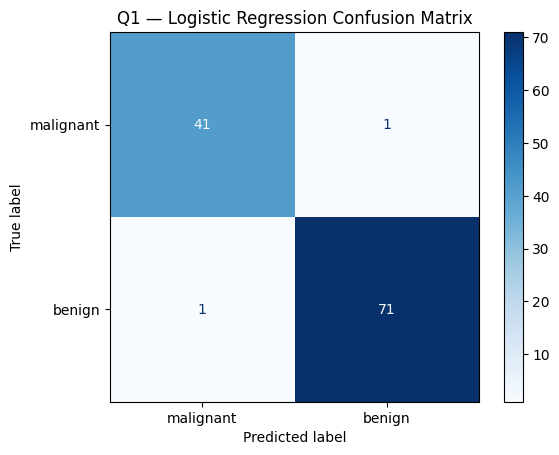

In [6]:
y_pred_logistic = logistic_model.predict(X_test_cancer)

logistic_metrics = {
    "Accuracy": accuracy_score(y_test_cancer, y_pred_logistic),
    "Precision (weighted)": precision_score(y_test_cancer, y_pred_logistic, average="weighted", zero_division=0),
    "Recall (weighted)": recall_score(y_test_cancer, y_pred_logistic, average="weighted", zero_division=0),
    "F1-score (weighted)": f1_score(y_test_cancer, y_pred_logistic, average="weighted", zero_division=0)
}

print("Logistic Regression evaluation:")
for metric, value in logistic_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test_cancer, y_pred_logistic,
    labels=[0, 1], target_names=cancer.target_names, zero_division=0
))

cm_logistic = confusion_matrix(y_test_cancer, y_pred_logistic, labels=[0, 1])
print("Confusion matrix (rows = actual, columns = predicted; order = malignant, benign):")
print(cm_logistic)

ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=cancer.target_names
).plot(cmap="Blues", values_format="d")
plt.title("Q1 — Logistic Regression Confusion Matrix")
plt.show()

In [7]:
prediction_examples = pd.DataFrame({
    "Actual class": [cancer.target_names[i] for i in y_test_cancer.iloc[:10]],
    "Predicted class": [cancer.target_names[i] for i in y_pred_logistic[:10]],
    "Correct?": (y_test_cancer.iloc[:10].to_numpy() == y_pred_logistic[:10])
})
display(prediction_examples)

print("Why Logistic Regression is suitable:")
print(
    "Logistic Regression is designed for classification and estimates class probabilities. "
    "This task has two predefined classes (benign and malignant), so it is a binary "
    "classification problem. Scaling helps because the numerical features have different ranges."
)

,Actual class,Predicted class,Correct?
0,malignant,malignant,True
1,benign,benign,True
2,malignant,malignant,True
3,benign,benign,True
4,malignant,malignant,True
5,benign,benign,True
6,benign,benign,True
7,malignant,malignant,True
8,malignant,malignant,True
9,malignant,malignant,True


Why Logistic Regression is suitable:
Logistic Regression is designed for classification and estimates class probabilities. This task has two predefined classes (benign and malignant), so it is a binary classification problem. Scaling helps because the numerical features have different ranges.


In [8]:
iris = load_iris(as_frame=True)
X_iris = iris.data
y_iris = iris.target

print("Dataset loaded successfully.")
print("Number of rows:", X_iris.shape[0])
print("Number of input features:", X_iris.shape[1])
print("Feature names:", list(X_iris.columns))
print("Target mapping:", {i: name for i, name in enumerate(iris.target_names)})
display(X_iris.head())

print("\nClass distribution:")
print(y_iris.value_counts().sort_index().rename(index=dict(enumerate(iris.target_names))))

Dataset loaded successfully.
Number of rows: 150
Number of input features: 4
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target mapping: {0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')}


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Class distribution:
target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [9]:
print("Dataset information:")
X_iris.info()

print("\nMissing values in each feature:")
print(X_iris.isnull().sum())
print("\nDescriptive statistics:")
display(X_iris.describe())

print("Total missing feature values:", int(X_iris.isnull().sum().sum()))
print("Duplicate rows:", int(X_iris.duplicated().sum()))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB

Missing values in each feature:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

Descriptive statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Total missing feature values: 0
Duplicate rows: 1


In [10]:
X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris, y_iris,
    test_size=0.20,
    random_state=42,
    stratify=y_iris
)

print("Training samples:", X_train_iris.shape[0])
print("Testing samples:", X_test_iris.shape[0])
print("Training class counts:")
print(y_train_iris.value_counts().sort_index())
print("Testing class counts:")
print(y_test_iris.value_counts().sort_index())

Training samples: 120
Testing samples: 30
Training class counts:
target
0    40
1    40
2    40
Name: count, dtype: int64
Testing class counts:
target
0    10
1    10
2    10
Name: count, dtype: int64



================== K = 3 ==================
Accuracy: 0.9333
Confusion matrix (rows = actual, columns = predicted):
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


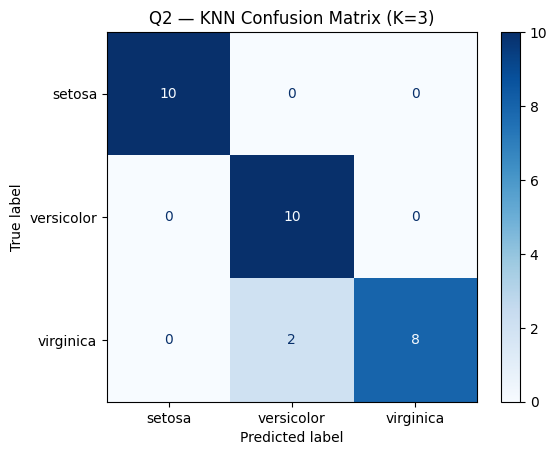


================== K = 5 ==================
Accuracy: 0.9333
Confusion matrix (rows = actual, columns = predicted):
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


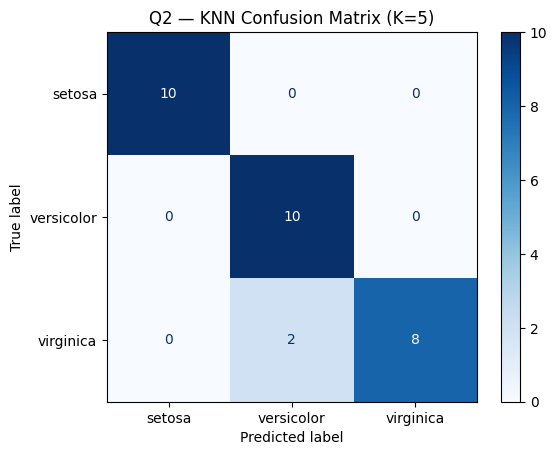


================== K = 7 ==================
Accuracy: 0.9667
Confusion matrix (rows = actual, columns = predicted):
[[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]


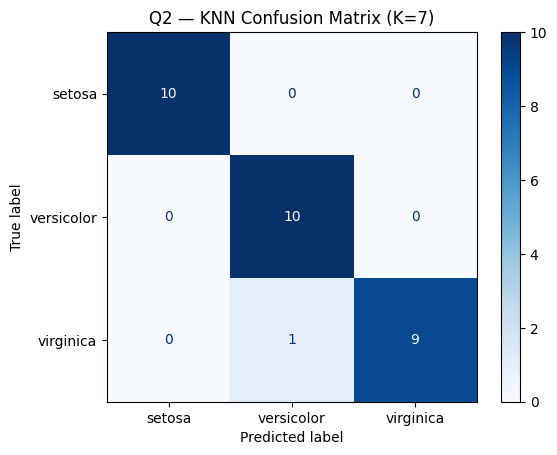


Accuracy comparison:


,K,Accuracy
0,7,0.966667
1,3,0.933333
2,5,0.933333


Best K on this selected test set: K = 7
Test accuracy: 0.9667


In [11]:
k_values = [3, 5, 7]
knn_results = []
knn_models = {}
knn_predictions = {}
knn_confusion_matrices = {}

for k in k_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])
    model.fit(X_train_iris, y_train_iris)
    y_pred = model.predict(X_test_iris)

    acc = accuracy_score(y_test_iris, y_pred)
    cm = confusion_matrix(y_test_iris, y_pred, labels=[0, 1, 2])

    knn_models[k] = model
    knn_predictions[k] = y_pred
    knn_confusion_matrices[k] = cm
    knn_results.append({"K": k, "Accuracy": acc})

    print(f"\n{'='*18} K = {k} {'='*18}")
    print(f"Accuracy: {acc:.4f}")
    print("Confusion matrix (rows = actual, columns = predicted):")
    print(cm)
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=iris.target_names
    ).plot(cmap="Blues", values_format="d")
    plt.title(f"Q2 — KNN Confusion Matrix (K={k})")
    plt.show()

knn_results_df = pd.DataFrame(knn_results).sort_values(
    by=["Accuracy", "K"], ascending=[False, True]
).reset_index(drop=True)

print("\nAccuracy comparison:")
display(knn_results_df)

best_k = int(knn_results_df.iloc[0]["K"])
print(f"Best K on this selected test set: K = {best_k}")
print(f"Test accuracy: {knn_results_df.iloc[0]['Accuracy']:.4f}")

In [12]:
print("KNN conclusion:")
print(
    f"Among K = 3, 5, and 7, K = {best_k} achieved the highest accuracy "
    f"on this test split ({knn_results_df.iloc[0]['Accuracy']:.4f})."
)
print(
    "KNN classifies by similarity: the nearest training flowers vote for the species. "
    "Feature scaling is important because measurements with larger numeric ranges "
    "could otherwise dominate distance calculations."
)

KNN conclusion:
Among K = 3, 5, and 7, K = 7 achieved the highest accuracy on this test split (0.9667).
KNN classifies by similarity: the nearest training flowers vote for the species. Feature scaling is important because measurements with larger numeric ranges could otherwise dominate distance calculations.


In [13]:
print("Training samples:", X_train_cancer.shape[0])
print("Testing samples:", X_test_cancer.shape[0])
print("Input features:", X_cancer.shape[1])
print("Target mapping:", {i: name for i, name in enumerate(cancer.target_names)})

Training samples: 455
Testing samples: 114
Input features: 30
Target mapping: {0: np.str_('malignant'), 1: np.str_('benign')}


In [14]:
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(kernel="rbf"))
])

svm_model.fit(X_train_cancer, y_train_cancer)
print("SVM model trained successfully.")

SVM model trained successfully.


SVM evaluation:
Accuracy: 0.9825
Precision (weighted): 0.9825
Recall (weighted): 0.9825
F1-score (weighted): 0.9825

Classification report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Confusion matrix (rows = actual, columns = predicted; order = malignant, benign):
[[41  1]
 [ 1 71]]


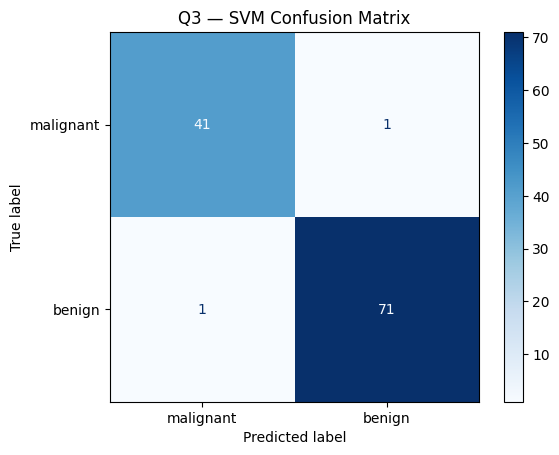

In [15]:
y_pred_svm = svm_model.predict(X_test_cancer)

svm_metrics = {
    "Accuracy": accuracy_score(y_test_cancer, y_pred_svm),
    "Precision (weighted)": precision_score(y_test_cancer, y_pred_svm, average="weighted", zero_division=0),
    "Recall (weighted)": recall_score(y_test_cancer, y_pred_svm, average="weighted", zero_division=0),
    "F1-score (weighted)": f1_score(y_test_cancer, y_pred_svm, average="weighted", zero_division=0)
}

print("SVM evaluation:")
for metric, value in svm_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test_cancer, y_pred_svm,
    labels=[0, 1], target_names=cancer.target_names, zero_division=0
))

cm_svm = confusion_matrix(y_test_cancer, y_pred_svm, labels=[0, 1])
print("Confusion matrix (rows = actual, columns = predicted; order = malignant, benign):")
print(cm_svm)

ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=cancer.target_names
).plot(cmap="Blues", values_format="d")
plt.title("Q3 — SVM Confusion Matrix")
plt.show()

In [16]:
comparison_df = pd.DataFrame([
    {"Model": "Logistic Regression", **logistic_metrics},
    {"Model": "SVM (RBF kernel)", **svm_metrics}
])

print("Model comparison:")
display(comparison_df)

# Identify the model with higher test accuracy
if svm_metrics["Accuracy"] > logistic_metrics["Accuracy"]:
    winner = "SVM (RBF kernel)"
elif logistic_metrics["Accuracy"] > svm_metrics["Accuracy"]:
    winner = "Logistic Regression"
else:
    winner = "Tie"

print("Comparison based on test accuracy:", winner)

Model comparison:


,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
0,Logistic Regression,0.982456,0.982456,0.982456,0.982456
1,SVM (RBF kernel),0.982456,0.982456,0.982456,0.982456


Comparison based on test accuracy: Tie
